# E3 — Coordination Graph Baseline

**Mục tiêu:** xây dựng graph dùng chung hashtag và tìm cộng đồng tài khoản bằng Leiden.

**Cách chạy:** chạy lần lượt 7 code cell trên CPU: kết nối Drive → kiểm tra input → xử lý duplicate → dựng graph và Leiden → xuất evidence → kiểm tra output → tổng hợp kết quả.

**Thiết kế:** node là tài khoản; event là một hashtag trong một giờ UTC. Giữ event có 2–100 tài khoản. Weight là số event dùng chung, giữ cạnh có weight ≥ 2. Mỗi tài khoản chỉ đóng góp một lần trong mỗi event.

**Duplicate:** loại các tweet ID có xung đột metadata/text trong audit B/C; các ID còn lại giữ bản ghi đầu tiên.

**Output:** các bảng graph, community, audit, evidence, hình minh họa, cấu hình và báo cáo trong `E3_outputs`.

**Diễn giải:** graph dùng toàn bộ corpus để phân tích mô tả. Nhãn Bad/Good chỉ dùng mô tả cộng đồng sau khi dựng graph; chưa có ground-truth campaign để đánh giá độ chính xác phát hiện chiến dịch.


In [1]:
# E3 — 1. Kết nối Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# E3 — 2. Cấu hình và kiểm tra input
%pip install -q igraph leidenalg

from pathlib import Path
import json, hashlib, sys, platform, unicodedata, math
from collections import Counter, defaultdict
from itertools import combinations

import pandas as pd
import networkx as nx
import igraph as ig
import leidenalg

from IPython.display import display


# ============================================================
# ĐƯỜNG DẪN
# ============================================================

# Folder MXH là shortcut đã thêm vào My Drive
BASE = Path('/content/drive/MyDrive')

# Dữ liệu shared nằm trong MXH/processed
DATA = BASE / 'MXH' / 'processed'

# Output của E3 lưu riêng trong My Drive
OUT = BASE / 'E3_outputs'


# ============================================================
# CONFIG E3
# ============================================================

SEED = 42

RESOLUTION = 1.0

# -1 = Leiden chạy cho đến khi không còn cải thiện
LEIDEN_ITERATIONS = -1

# 1 giờ = 3600 giây
WINDOW_SECONDS = 3600

# Bỏ event có quá nhiều account
MAX_USERS_PER_EVENT = 100

# Hai account phải có ít nhất 2 shared events mới tạo edge
MIN_WEIGHT = 2

# Bảo vệ RAM / thời gian chạy
MAX_PAIR_UPDATES = 20_000_000


# ============================================================
# INPUT FILES
# ============================================================

FILES = [
    DATA / 'honduras_bad_normalized.jsonl',
    DATA / 'honduras_good_normalized.jsonl'
]

MANIFEST_FILE = DATA / 'honduras_account_manifest.csv'
SPLIT_FILE = DATA / 'honduras_account_splits.csv'

required = FILES + [
    MANIFEST_FILE,
    SPLIT_FILE
]


# ============================================================
# KIỂM TRA FILE CÓ TỒN TẠI KHÔNG
# ============================================================

print("DATA folder:", DATA)
print()

for p in required:
    print(
        "✅" if p.is_file() else "❌",
        p
    )

assert DATA.is_dir(), (
    f'Không thấy thư mục {DATA}. '
    'Kiểm tra Drive đã mount và shortcut MXH đã nằm trong My Drive.'
)

for p in required:
    assert p.is_file(), (
        f'Không thấy {p}. '
        'Kiểm tra shortcut MXH và đường dẫn DATA.'
    )


# ============================================================
# TẠO OUTPUT FOLDER
# ============================================================

OUT.mkdir(
    parents=True,
    exist_ok=True
)

print()
print("Output folder:", OUT)


# ============================================================
# ĐỌC MANIFEST + SPLIT
# ============================================================

manifest = pd.read_csv(
    MANIFEST_FILE,
    dtype={'user_id': str}
)

splits = pd.read_csv(
    SPLIT_FILE,
    dtype={'user_id': str}
)


# ============================================================
# VALIDATE MANIFEST / SPLIT
# ============================================================

assert manifest.user_id.notna().all()
assert manifest.user_id.is_unique

assert splits.user_id.notna().all()
assert splits.user_id.is_unique

assert set(manifest.user_id) == set(splits.user_id)

assert len(manifest) == 224685, (
    'Manifest khác phiên bản đã thống nhất; '
    'cần kiểm tra lại.'
)

assert splits['split'].notna().all()

assert set(splits['split']) <= {
    'train',
    'validation',
    'val',
    'test'
}


# Kiểm tra label giữa manifest và split nếu split có label
if 'label' in splits.columns:

    check = manifest[
        ['user_id', 'label']
    ].merge(
        splits[['user_id', 'label']],
        on='user_id',
        validate='one_to_one'
    )

    assert (
        check.label_x == check.label_y
    ).all()


# ============================================================
# LABEL MAP
# ============================================================

labels = (
    manifest
    .set_index('user_id')['label']
    .astype(int)
    .to_dict()
)

assert set(labels.values()) == {0, 1}

assert Counter(labels.values()) == {
    0: 1866,
    1: 222819
}

split_map = (
    splits
    .set_index('user_id')['split']
    .to_dict()
)


# ============================================================
# HIỂN THỊ THỐNG KÊ
# ============================================================

print()
print(
    'Accounts:',
    len(labels),
    '| label 0=Bad, 1=Good'
)

display(
    splits
    .groupby('split')
    .size()
    .rename('accounts')
)


# ============================================================
# KIỂM TRA SCHEMA JSONL
# ============================================================

for p in FILES:

    with p.open(
        encoding='utf-8'
    ) as f:

        sample = json.loads(
            next(f)
        )

    required_fields = {
        'account_id',
        'tweet_id',
        'created_at',
        'hashtags',
        'label',
        'text'
    }

    assert required_fields <= sample.keys(), (
        f'{p.name} thiếu field. '
        f'Có: {sample.keys()}'
    )

    print()
    print(
        p.name,
        {
            k: sample[k]
            for k in [
                'created_at',
                'hashtags',
                'label'
            ]
        }
    )


# ============================================================
# ENVIRONMENT
# ============================================================

print()
print(
    'NetworkX:',
    nx.__version__
)

print(
    'DATA:',
    DATA
)

print(
    'OUTPUT:',
    OUT
)

print()
print('✅ PASS: Input E3 hợp lệ.')

DATA folder: /content/drive/MyDrive/MXH/processed

✅ /content/drive/MyDrive/MXH/processed/honduras_bad_normalized.jsonl
✅ /content/drive/MyDrive/MXH/processed/honduras_good_normalized.jsonl
✅ /content/drive/MyDrive/MXH/processed/honduras_account_manifest.csv
✅ /content/drive/MyDrive/MXH/processed/honduras_account_splits.csv

Output folder: /content/drive/MyDrive/E3_outputs

Accounts: 224685 | label 0=Bad, 1=Good


,accounts
split,
test,44938
train,157279
validation,22468



honduras_bad_normalized.jsonl {'created_at': 1576857900000, 'hashtags': [], 'label': 0}

honduras_good_normalized.jsonl {'created_at': 1578527640000, 'hashtags': ['AlivioDeDeuda'], 'label': 1}

NetworkX: 3.7
DATA: /content/drive/MyDrive/MXH/processed
OUTPUT: /content/drive/MyDrive/E3_outputs

✅ PASS: Input E3 hợp lệ.


In [3]:
# E3 — 3. Đọc streaming, xử lý duplicate, tạo sự kiện hashtag–giờ UTC
# Exact IDs: giữ lần đầu. Toàn bộ occurrence của metadata/text-conflict IDs: loại.
from datetime import datetime, timezone
import re
AUDIT = DATA/'quality_audit'
conflicts = set()
for name in ['group_b_metadata_conflicts.csv','group_c_text_conflicts.csv']:
    p = AUDIT/name
    assert p.is_file(), f'Thiếu audit bắt buộc: {p}'
    q = pd.read_csv(p, dtype=str)
    assert 'tweet_id' in q.columns
    conflicts.update(q.tweet_id.dropna())

def timestamp_seconds(value):
    if value is None or value == '':
        return None
    s = str(value).strip()
    try:
        if s.lstrip('-').replace('.', '', 1).isdigit():
            x = float(s)
            if abs(x) > 1e11: x /= 1000
            return int(x) if 946684800 <= x <= 4102444800 else None
        d = datetime.fromisoformat(s.replace('Z','+00:00'))
        if d.tzinfo is None: d = d.replace(tzinfo=timezone.utc)
        return int(d.timestamp())
    except (ValueError, OverflowError):
        t = pd.to_datetime(s, utc=True, errors='coerce')
        return None if pd.isna(t) else int(t.timestamp())

def tags_of(value):
    assert isinstance(value, list), f'hashtags cần là list, nhận {type(value)}'
    result = set()
    for item in value:
        if isinstance(item, dict): item = item.get('text', item.get('tag',''))
        assert isinstance(item, str), 'Hashtag sai schema'
        tag = unicodedata.normalize('NFKC', item).strip().lstrip('#').casefold()
        if tag: result.add(tag)
    return sorted(result)

events = defaultdict(set)
seen = set()
observed_accounts = set()
quality = Counter()
source_rows = Counter()
input_hashes = {}
for file_index, p in enumerate(FILES):
    sha = hashlib.sha256()
    with p.open('rb') as f:
        for line_no, raw in enumerate(f, 1):
            sha.update(raw)
            if not raw.strip(): continue
            obj = json.loads(raw)
            quality['raw_rows'] += 1
            source_rows[p.name] += 1
            aid, tid = str(obj['account_id']), str(obj['tweet_id'])
            assert aid in labels, f'Account không nằm trong manifest: {aid}'
            assert int(obj['label']) == labels[aid] == file_index
            observed_accounts.add(aid)
            if tid in conflicts:
                quality['conflict_rows_removed'] += 1
                continue
            assert tid not in ('','None','nan'), 'Missing tweet ID'
            if tid in seen:
                quality['duplicate_rows_removed'] += 1
                continue
            seen.add(tid)
            ts = timestamp_seconds(obj['created_at'])
            if ts is None:
                quality['invalid_timestamp_rows'] += 1
                continue
            quality['retained_valid_rows'] += 1
            tags = tags_of(obj.get('hashtags') or [])
            if not tags: quality['rows_without_hashtag'] += 1
            for tag in tags:
                events[(tag, ts // WINDOW_SECONDS)].add(aid)
    input_hashes[p.name] = sha.hexdigest()
    print(p.name, 'rows:',source_rows[p.name])
assert observed_accounts == set(labels), 'Account coverage không khớp manifest'
assert list(source_rows.values()) == [137252,1125578], 'Số record khác phiên bản đã audit'
quality['conflict_ids_excluded'] = len(conflicts)
quality['unique_retained_tweet_ids'] = len(seen)
quality['hashtag_time_events'] = len(events)
pd.DataFrame(sorted(quality.items()),columns=['metric','value']).to_csv(OUT/'e3_data_quality.csv',index=False)
display(pd.Series(quality))
print('Ví dụ event:', next(iter(events.items()), None))


honduras_bad_normalized.jsonl rows: 137252
honduras_good_normalized.jsonl rows: 1125578


,0
raw_rows,1262830
retained_valid_rows,1254185
rows_without_hashtag,237730
conflict_rows_removed,1362
duplicate_rows_removed,7283
conflict_ids_excluded,389
unique_retained_tweet_ids,1254185
hashtag_time_events,403043


Ví dụ event: (('ciudadmujerjuticalpa', 437330), {'1191513076530634752', '1192953832956977152', '1191783059546398720', '1194977727683661824', '1194990564942516224', '1195353965547999232', '1191105781560758272', '1191725807275778048', '1194989483265015808', '1191144767649992704', '392378363', '1196139271947718656', '1187084594874585091', '1196136910546251776', '1191155384846864384', '1192973444952084480', '1182491964970807296', '1191147542135951360', '1191509273551032320', '1191518977585025024', '1192950930783768576', '1195348811566211072', '1191091027446239232', '1193635050992082944', '1183414966411583488', '1190303283329617927', '1191152148190511104', '1196134831723352064', '1192984606590603264', '1058142970153713665', '1191504807724552192', '1191734068049784832', '1191149569503121408', '1196110974199181312', '1191136071742107648', '1196137871968743424', '1192986463585079296', '1191790017519267840', '1192989258195361792', '1191107773041385472', '1195346901761241088', '11915163496647680

In [4]:
# E3 — 4. Dựng graph vô hướng có trọng số và chạy Leiden
# Mỗi account tính một lần/event (hashtag, giờ UTC).
# Weight là số event dùng chung; chỉ giữ cạnh đạt MIN_WEIGHT.
pair_weights = Counter()
event_audit = []
pair_updates = 0
for (tag, bucket), users in sorted(events.items()):
    n = len(users)
    status = 'kept' if 2 <= n <= MAX_USERS_PER_EVENT else ('singleton' if n < 2 else 'too_popular')
    event_audit.append((tag,bucket,n,status))
    if status != 'kept': continue
    pair_updates += n*(n-1)//2
    if pair_updates > MAX_PAIR_UPDATES:
        raise RuntimeError('Vượt pair budget. Giảm MAX_USERS_PER_EVENT và chạy lại từ cell 4; ghi rõ cấu hình mới.')
    pair_weights.update(combinations(sorted(users),2))
edge_rows = [(a,b,w) for (a,b),w in sorted(pair_weights.items()) if w >= MIN_WEIGHT]
edges = pd.DataFrame(edge_rows,columns=['source','target','weight'])
G = nx.Graph()
G.add_nodes_from(sorted(labels))
G.add_weighted_edges_from(edge_rows)
assert nx.number_of_selfloops(G) == 0
H = nx.Graph()
H.add_nodes_from(sorted(n for n, d in G.degree() if d > 0))
H.add_weighted_edges_from(sorted(
    (min(u, v), max(u, v), data["weight"])
    for u, v, data in G.edges(data=True)
))
if H.number_of_edges():
    # Ánh xạ account ID sang vertex index theo thứ tự cố định.
    active_ids = sorted(H.nodes())
    vertex_index = {u: i for i, u in enumerate(active_ids)}
    active_edges = sorted((min(u, v), max(u, v), d['weight'])
                          for u, v, d in H.edges(data=True))
    leiden_graph = ig.Graph(n=len(active_ids),
        edges=[(vertex_index[u], vertex_index[v]) for u, v, w in active_edges],
        directed=False)
    leiden_graph.es['weight'] = [w for u, v, w in active_edges]
    partition = leidenalg.find_partition(
        leiden_graph, leidenalg.RBConfigurationVertexPartition,
        weights='weight', resolution_parameter=RESOLUTION,
        n_iterations=LEIDEN_ITERATIONS, seed=SEED)
    communities = [{active_ids[i] for i in group} for group in partition]
    communities = sorted(communities,key=lambda c:(-len(c),min(c)))
    modularity = nx.community.modularity(H,communities,weight='weight',resolution=RESOLUTION)
else:
    communities, modularity = [], None
membership = {u:i for i,c in enumerate(communities) for u in c}
nodes = pd.DataFrame([dict(account_id=u,label=labels[u],split=split_map[u],
    degree=G.degree(u),strength=G.degree(u,weight='weight'),
    community=membership.get(u,-1)) for u in sorted(G)])
# -1 = isolate, không gom tất cả isolate thành một community thật.
components = sorted(nx.connected_components(G),key=lambda c:(-len(c),min(c)))
metrics = dict(experiment='E3',method='hashtag_hour_leiden',scope='full_corpus_descriptive_transductive',
    seed=SEED,resolution=RESOLUTION,leiden_iterations=LEIDEN_ITERATIONS,window_seconds=WINDOW_SECONDS,max_users_per_event=MAX_USERS_PER_EVENT,
    min_weight=MIN_WEIGHT,n_nodes=len(G),n_active_nodes=len(H),n_edges=G.number_of_edges(),
    n_isolates=nx.number_of_isolates(G),density=nx.density(G),
    n_components=len(components),largest_component_nodes=len(components[0]) if components else 0,
    n_communities=len(communities),largest_community_nodes=len(communities[0]) if communities else 0,
    modularity=modularity,pair_updates=pair_updates,
    dropped_popular_events=sum(r[3]=='too_popular' for r in event_audit))
edges.to_csv(OUT/'e3_graph_edges.csv',index=False)
nodes.to_csv(OUT/'e3_graph_nodes.csv',index=False)
pd.DataFrame([metrics]).to_csv(OUT/'e3_graph_metrics.csv',index=False)
pd.DataFrame(event_audit,columns=['hashtag','time_bucket','n_accounts','status']).to_csv(OUT/'e3_event_audit.csv',index=False)
pd.DataFrame([(i,len(c)) for i,c in enumerate(components)],columns=['component','n_nodes']).to_csv(OUT/'e3_components.csv',index=False)
display(pd.DataFrame([metrics]).T)
print('Leiden chạy trên active graph; isolate vẫn được lưu trong node table.')


,0
experiment,E3
method,hashtag_hour_leiden
scope,full_corpus_descriptive_transductive
seed,42
resolution,1.0
leiden_iterations,-1
window_seconds,3600
max_users_per_event,100
min_weight,2
n_nodes,224685


Leiden chạy trên active graph; isolate vẫn được lưu trong node table.


In [5]:
# E3 — 5. Community summary và bằng chứng để kiểm tra thủ công
summary_rows = []
for cid, c in enumerate(communities):
    sub = H.subgraph(c)
    bad = sum(labels[u]==0 for u in c)
    summary_rows.append(dict(community=cid,n_nodes=len(c),n_edges=sub.number_of_edges(),
        density=nx.density(sub),bad_accounts=bad,good_accounts=len(c)-bad,bad_ratio=bad/len(c)))
summary = pd.DataFrame(summary_rows,columns=['community','n_nodes','n_edges','density','bad_accounts','good_accounts','bad_ratio'])
summary.to_csv(OUT/'e3_communities.csv',index=False)
display(summary.head(10))
# Chọn tối đa 3 community lớn nhất, cạnh mạnh nhất mỗi community (tie-break ID).
picked = []
for cid,c in enumerate(communities[:3]):
    candidate = sorted(((a,b,d['weight']) for a,b,d in H.subgraph(c).edges(data=True)),key=lambda r:(-r[2],r[0],r[1]))
    if candidate: picked.append((cid,*candidate[0]))
targets = defaultdict(list)
for cid,a,b,w in picked:
    shared = [(tag,bucket) for (tag,bucket),us in sorted(events.items())
              if 2 <= len(us) <= MAX_USERS_PER_EVENT and a in us and b in us][:3]
    assert len(shared) >= min(3,w)
    for tag,bucket in shared:
        for aid in [a,b]: targets[(aid,tag,bucket)].append((cid,a,b,w))
evidence, used_ids, captured = [], set(), set()
for p in FILES:
    with p.open(encoding='utf-8') as f:
        for raw in f:
            if not raw.strip(): continue
            obj = json.loads(raw)
            tid, aid = str(obj['tweet_id']), str(obj['account_id'])
            if tid in conflicts or tid in used_ids: continue
            used_ids.add(tid)
            ts = timestamp_seconds(obj['created_at'])
            if ts is None: continue
            for tag in tags_of(obj.get('hashtags') or []):
                key = (aid,tag,ts//WINDOW_SECONDS)
                if key not in targets or key in captured: continue
                captured.add(key)
                for cid,a,b,w in targets[key]:
                    evidence.append(dict(community=cid,source=a,target=b,weight=w,
                        hashtag=tag,time_bucket=key[2],account_id=aid,tweet_id=tid,
                        created_at=str(obj['created_at']),text=obj['text'],
                        review_status='pending',review_note=''))
review = pd.DataFrame(evidence,columns=['community','source','target','weight','hashtag','time_bucket',
    'account_id','tweet_id','created_at','text','review_status','review_note'])
assert set(targets) <= captured, 'Thiếu evidence cho một số event'
review.to_csv(OUT/'e3_manual_review.csv',index=False)
display(review)
print('Đọc từng cặp text/time/hashtag; điền review_status và review_note trong CSV.')
print('Không tự đánh dấu đã review. Hashtag/time trùng có thể là tin tức hoặc hoạt động tự nhiên.')


,community,n_nodes,n_edges,density,bad_accounts,good_accounts,bad_ratio
0,0,17517,389307,0.002538,1,17516,0.000057
1,1,12579,312151,0.003946,0,12579,0.000000
2,2,10533,374899,0.006759,0,10533,0.000000
3,3,9243,44465,0.001041,0,9243,0.000000
4,4,4288,30880,0.003360,0,4288,0.000000
5,5,3366,53849,0.009508,0,3366,0.000000
6,6,3065,33365,0.007106,0,3065,0.000000
7,7,2420,29144,0.009957,0,2420,0.000000
8,8,2266,27515,0.010722,0,2266,0.000000
9,9,2102,31382,0.014212,0,2102,0.000000


,community,source,target,weight,hashtag,time_bucket,account_id,tweet_id,created_at,text,review_status,review_note
0,1,1071499269880901639,955569674737127425,53,2ene,438338,955569674737127425,1212917957199876096,1578017100000,RT @ChalecosAmarill: 📽🆘️ #2Ene || #Irak 🇮🇶\n\n...,pending,
1,1,1071499269880901639,955569674737127425,53,2ene,438338,1071499269880901639,1212917807488360449,1578017100000,RT @ChalecosAmarill: 📽🆘️ #2Ene || #Irak 🇮🇶\n\n...,pending,
2,1,1071499269880901639,955569674737127425,53,alerta,438337,955569674737127425,1212915629168250880,1578016560000,RT @ChalecosAmarill: 🚨 #ALERTA 🚨 ‼️FURIA CONTR...,pending,
3,1,1071499269880901639,955569674737127425,53,alerta,438337,1071499269880901639,1212915436502835207,1578016500000,🚨 #ALERTA 🚨 ‼️FURIA CONTRA #EEUU 🇺🇸‼️\n\n#USA ...,pending,
4,1,1071499269880901639,955569674737127425,53,2ene,438337,1071499269880901639,1212911628448149504,1578015600000,RT @ChalecosAmarill: 📽🆘️ #2Ene || ⚠️ #ALERTA ⚠...,pending,
5,1,1071499269880901639,955569674737127425,53,2ene,438337,955569674737127425,1212901449837006848,1578013200000,RT @ChalecosAmarill: 📽🆘️ #2Ene || ⚠️ #ALERTA ⚠...,pending,
6,2,118837580,1171942652255907840,628,15dic,437902,1171942652255907840,1206337175995990016,1576448160000,RT @Guajiritasoy: #Cuba #15Dic #LoDijo #Eduard...,pending,
7,2,118837580,1171942652255907840,628,15dic,437902,118837580,1206336929765220358,1576448100000,RT @Guajiritasoy: #Cuba #15Dic #LoDijo #Eduard...,pending,
8,2,118837580,1171942652255907840,628,15nov,437169,1171942652255907840,1195274819140493312,1573810680000,RT @AmbassadorCuba: Cotidiano oficialista #Gam...,pending,
9,2,118837580,1171942652255907840,628,15nov,437169,118837580,1195273591278964737,1573810380000,RT @AmbassadorCuba: Cotidiano oficialista #Gam...,pending,


Đọc từng cặp text/time/hashtag; điền review_status và review_note trong CSV.
Không tự đánh dấu đã review. Hashtag/time trùng có thể là tin tức hoặc hoạt động tự nhiên.


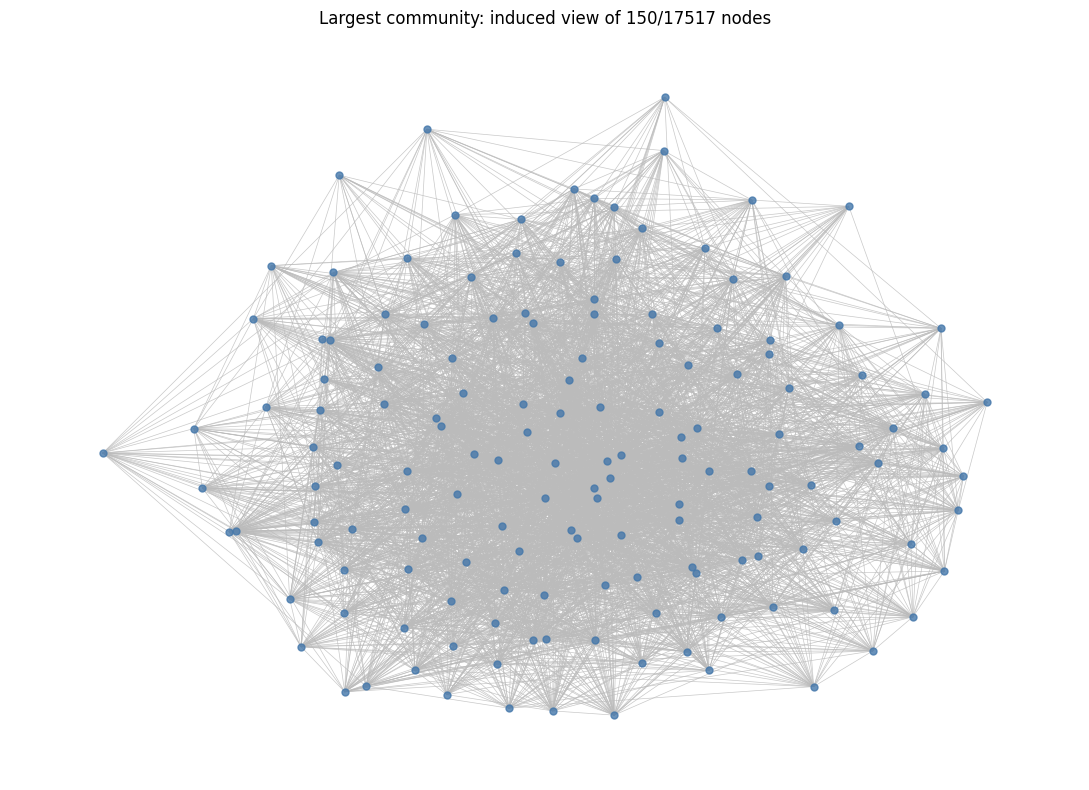

PASS: output reload checks. Kết quả: /content/drive/MyDrive/E3_outputs
E3_RESULTS.md 3099 bytes
README.md 4300 bytes
e3_communities.csv 46373 bytes
e3_community_preview.png 1537158 bytes
e3_components.csv 1164710 bytes
e3_data_quality.csv 228 bytes
e3_event_audit.csv 11234284 bytes
e3_graph_edges.csv 56096937 bytes
e3_graph_metrics.csv 464 bytes
e3_graph_nodes.csv 6491514 bytes
e3_manual_review.csv 4776 bytes
e3_run_config.json 1465 bytes
e3_split_counts.csv 58 bytes
requirements_e3.txt 79 bytes


In [6]:
# E3 — 6. Hình minh họa, kiểm tra output và README tái lập
import matplotlib.pyplot as plt
import importlib.metadata as metadata
# Chỉ minh họa tối đa 150 node có weighted degree cao trong community lớn nhất.
# Thống kê ở cell 4/5 vẫn tính trên graph đầy đủ.
if communities:
    chosen = sorted(communities[0],key=lambda u:(-H.degree(u,weight='weight'),u))[:150]
    P = H.subgraph(sorted(chosen)).copy()
    plt.figure(figsize=(11,8))
    pos = nx.spring_layout(P,seed=SEED,weight='weight')
    nx.draw_networkx(P,pos,node_size=25,with_labels=False,
        node_color='#4477AA',edge_color='#BBBBBB',width=0.5,alpha=0.8)
    plt.title(f'Largest community: induced view of {len(P)}/{len(communities[0])} nodes')
    plt.axis('off'); plt.tight_layout()
    plt.savefig(OUT/'e3_community_preview.png',dpi=180)
    plt.show()
# Kiểm tra reload IDs dưới dạng string để tránh mất chính xác tweet/account IDs.
echeck = pd.read_csv(OUT/'e3_graph_edges.csv',dtype={'source':str,'target':str})
ncheck = pd.read_csv(OUT/'e3_graph_nodes.csv',dtype={'account_id':str})
assert len(echeck) == G.number_of_edges()
assert ncheck.account_id.is_unique and set(ncheck.account_id)==set(labels)
assert (echeck.weight >= MIN_WEIGHT).all()
assert (echeck.source != echeck.target).all()
assert sum(ncheck.degree) == 2*len(echeck)
assert (ncheck['label'].astype(int) == ncheck.account_id.map(labels)).all()
assert (ncheck['split'] == ncheck.account_id.map(split_map)).all()
for p in required[2:] + sorted(AUDIT.glob('group_*.csv')):
    input_hashes[str(p.relative_to(DATA))] = hashlib.sha256(p.read_bytes()).hexdigest()
config = dict(algorithm='leiden',partition_type='RBConfigurationVertexPartition',
    resolution=RESOLUTION,leiden_iterations=LEIDEN_ITERATIONS,seed=SEED,window_seconds=WINDOW_SECONDS,max_users_per_event=MAX_USERS_PER_EVENT,
    min_weight=MIN_WEIGHT,max_pair_updates=MAX_PAIR_UPDATES,
    graph_scope='full corpus, descriptive/transductive; no held-out predictive score',
    duplicate_policy='drop all B/C conflict IDs; retain first occurrence of other tweet IDs',
    label_mapping={'0':'Bad','1':'Good'},input_sha256=input_hashes,
    python=platform.python_version(),packages={p:metadata.version(p) for p in ['networkx','pandas','matplotlib','igraph','leidenalg']})
(OUT/'e3_run_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
(OUT/'requirements_e3.txt').write_text(''.join(p+'=='+v+chr(10) for p,v in config['packages'].items()),encoding='utf-8')
README = f'''# E3 — Coordination Graph Baseline
## Chạy lại
1. Mở E3_Coordination_Graph.ipynb trên Colab, dùng CPU runtime.
2. Chạy cell 1 và hoàn tất Google Drive mount bằng tài khoản có quyền đọc MXH.
3. DATA ở cell 2 trỏ đến MXH/processed qua shortcut trong MXH_4_output.
   Có thể sửa DATA nếu shortcut nằm ở vị trí khác. OUT hiện tại: {OUT}
4. Chạy lần lượt cell 2 → 7.
5. Kiểm tra bảng metrics, community summary và e3_manual_review.csv.
   Điền review_status/review_note sau khi thực sự đọc evidence.
6. Lưu notebook bằng Ctrl+S. Outputs riêng tư của Colab có thể không nằm trong ipynb;
   các CSV/JSON/PNG được lưu riêng ở OUT.

## Input
Hai Honduras normalized JSONL, honduras_account_manifest.csv,
honduras_account_splits.csv, quality_audit/group_b_metadata_conflicts.csv,
quality_audit/group_c_text_conflicts.csv. Không cần Fox8 hay feature table E2.
Schema: account_id, tweet_id, label, text, created_at, hashtags.
Label 0=Bad, 1=Good; nhãn chỉ dùng mô tả hậu nghiệm, không dùng tạo graph.
File gốc chỉ đọc. Conflict IDs B/C bị loại toàn bộ; ID còn lại giữ occurrence đầu.

## Định nghĩa graph
Node: mọi account trong manifest, giữ cả isolate.
Event: một hashtag NFKC/casefold, bỏ # đầu, trong giờ UTC cố định 3600 giây.
Mỗi account chỉ tính một lần/event. Event có 2–{MAX_USERS_PER_EVENT} account mới được dùng.
Edge vô hướng: hai account cùng event; weight là số event khác nhau dùng chung.
Giữ weight >= {MIN_WEIGHT}, không self-loop. Không giới hạn số tweet theo label.
Leiden: igraph + leidenalg, RBConfigurationVertexPartition, weighted, resolution={RESOLUTION}, seed={SEED}, n_iterations={LEIDEN_ITERATIONS}, chạy trên active nodes.
Community -1 trong node table là isolate, không phải một community thật.

## Output
- e3_graph_edges.csv: source,target,weight
- e3_graph_nodes.csv: account_id,label,split,degree,strength,community
- e3_graph_metrics.csv: node/edge/isolate/component/community statistics, modularity
- e3_communities.csv, e3_components.csv: bảng thống kê
- e3_data_quality.csv, e3_event_audit.csv: số record bị loại và event bị bỏ
- e3_manual_review.csv: evidence của cạnh mạnh nhất trong tối đa 3 community lớn
- e3_community_preview.png: hình một phần community lớn nhất nếu graph có cạnh
- e3_run_config.json: cấu hình, SHA256 input và phiên bản runtime
- requirements_e3.txt: phiên bản package của lần chạy

## Giới hạn và cách diễn giải
Đây là baseline shared-hashtag coordination/community discovery, chưa xác nhận campaign.
Không có ground-truth campaign labels nên không báo Precision/Recall/F1 campaign.
Modularity và bad_ratio chỉ là mô tả, không chứng minh phối hợp độc hại.
Hashtag phổ biến, tin nóng, retweet cùng nội dung và chênh lệch mức hoạt động có thể tạo cạnh tự nhiên.
Giờ cố định có boundary effect; cùng hashtag ở hai giờ liền kề không nối nhau.
Ngưỡng event tối đa bỏ cả event phổ biến, làm mất một phần tín hiệu; audit ghi rõ số bị bỏ.
Threshold được khai báo trước, không chọn theo label/test. Chưa thực hiện sensitivity analysis.
Graph dùng toàn corpus (transductive/mô tả), giữ split làm metadata, không thay split E1/E2.
Không dùng graph này cho đánh giá inductive E2 nếu chưa thiết kế lại quy trình tránh leakage.
Nếu graph rỗng: báo đúng 0 cạnh; không âm thầm giảm ngưỡng để tạo kết quả đẹp.
Nếu vượt pair budget: chương trình dừng, không xuất graph cắt cụt; sửa cấu hình và chạy lại.

## Reproducibility checklist
[x] Kiểm tra số account và label, manifest/split không giao nhau theo account.
[x] Không dùng label hoặc split để chọn cạnh.
[x] Duplicate policy và input hashes được ghi lại.
[x] Seed và thứ tự node/edge được cố định.
[x] Reload output kiểm tra ID, degree, split, label.
[ ] Người thực hiện xác nhận review thủ công trong CSV.
[ ] Thành viên khác chạy toàn bộ trên runtime sạch và đối chiếu output.
'''
(OUT/'README.md').write_text(README,encoding='utf-8')
print('PASS: output reload checks. Kết quả:',OUT)
for p in sorted(OUT.iterdir()): print(p.name, p.stat().st_size, 'bytes')

split_counts = splits.groupby('split').size().to_dict()
pd.DataFrame(sorted(split_counts.items()),columns=['split','n_accounts']).to_csv(OUT/'e3_split_counts.csv',index=False)


In [7]:
# E3 — 7. Review evidence và báo cáo nhất quán với lần chạy hiện tại
import re

REVIEWER = 'Văn Nam'
REVIEW_DATE = '2026-10-25'
# Chỉ kế thừa nhận xét khi toàn bộ mẫu tweet/event khớp đúng mẫu đã đọc.
# Nếu rerun chọn evidence khác, giữ pending để kiểm tra lại.
reviewed_samples = {
    tuple(sorted(['955569674737127425', '1071499269880901639'])): {
        'evidence': {
            ('1212917957199876096', '2ene', 438338),
            ('1212917807488360449', '2ene', 438338),
            ('1212915629168250880', 'alerta', 438337),
            ('1212915436502835207', 'alerta', 438337),
            ('1212911628448149504', '2ene', 438337),
            ('1212901449837006848', '2ene', 438337),
        },
        'note': 'Đã đọc 3 event mẫu (6 dòng): hai account chia sẻ nội dung của ChalecosAmarill; một event cùng timestamp ghi nhận, một lệch 60 giây, một lệch 40 phút. Có shared amplification, nhưng chưa đủ bằng chứng kết luận campaign độc hại.'
    },
    tuple(sorted(['141160059', '145459615'])): {
        'evidence': {
            ('1193603688025210880', '10nov', 437058),
            ('1193595641269833730', '10nov', 437058),
            ('1193527460232671233', '10nov', 437053),
            ('1193527332998451201', '10nov', 437053),
            ('1179786606867341312', '03oct', 436143),
            ('1179779821452312576', '03oct', 436143),
        },
        'note': 'Đã đọc 3 event mẫu (6 dòng): hai event có nội dung DolarToday giống/gần giống dạng original–retweet, lệch 0 và 27 phút; event #10nov ở bucket 437058 lệch 32 phút nhưng text khác chủ đề. Hashtag ngày tháng có thể tạo cạnh yếu về ngữ nghĩa; chưa đủ kết luận phối hợp độc hại.'
    },
    tuple(sorted(['118837580', '1171942652255907840'])): {
        'evidence': {
            ('1206337175995990016', '15dic', 437902),
            ('1206336929765220358', '15dic', 437902),
            ('1195274819140493312', '15nov', 437169),
            ('1195273591278964737', '15nov', 437169),
            ('1193826485913686016', '11nov', 437073),
            ('1193826080886579200', '11nov', 437073),
        },
        'note': 'Đã đọc 3 event mẫu (6 dòng): #15dic cùng retweet của @Guajiritasoy, lệch 60 giây; #15nov và #11nov cùng retweet của @AmbassadorCuba, lệch lần lượt 300 và 120 giây theo timestamp ghi nhận. Các cặp text trong từng event giống nhau ở phần dữ liệu được cung cấp; một số tweet bị cắt bằng dấu … nên không khẳng định nội dung đầy đủ giống tuyệt đối. Phù hợp shared amplification cùng nguồn về Cuba; ba event không đủ xác nhận tự động hóa hoặc campaign độc hại. Weight 628 là số event hashtag–giờ chung, không phải 628 lần phối hợp độc lập.'
    },
}

review['review_status'] = 'pending'
review['review_note'] = ''
review['reviewer'] = ''
review['review_date'] = ''
review['review_assistance'] = ''
review_pairs = defaultdict(list)
for idx, row in review.iterrows():
    pair = tuple(sorted([str(row['source']), str(row['target'])]))
    review_pairs[pair].append(idx)

applied_notes = {}
for pair, indices in sorted(review_pairs.items()):
    sample = reviewed_samples.get(pair)
    group = review.loc[indices]
    signature = {(str(r.tweet_id), str(r.hashtag), int(r.time_bucket))
                 for r in group.itertuples()}
    if sample is not None and len(group) == len(sample['evidence']) and signature == sample['evidence']:
        review.loc[indices, 'review_status'] = 'reviewed_evidence_only'
        review.loc[indices, 'review_note'] = sample['note']
        review.loc[indices, 'reviewer'] = REVIEWER
        review.loc[indices, 'review_date'] = REVIEW_DATE
        review.loc[indices, 'review_assistance'] = 'ChatGPT'
        applied_notes[pair] = sample['note']

reviewed_mask = review.review_status.eq('reviewed_evidence_only')
n_reviewed = int(reviewed_mask.sum())
n_pending = int((~reviewed_mask).sum())
n_pairs = len(review_pairs)
n_reviewed_pairs = len(applied_notes)
review.to_csv(OUT/'e3_manual_review.csv', index=False)
# Xác nhận tên người review và trạng thái trong CSV đã lưu.
review_check = pd.read_csv(OUT/'e3_manual_review.csv', dtype=str, keep_default_na=False)
assert len(review_check) == len(review)
assert review_check.review_status.tolist() == review.review_status.tolist()
assert review_check.loc[reviewed_mask.to_numpy(), 'reviewer'].eq(REVIEWER).all()

report = f'''# E3 — Kết quả baseline Leiden

Dữ liệu: {quality['raw_rows']:,} records ban đầu; giữ {quality['retained_valid_rows']:,} tweet hợp lệ sau lọc.
Loại {quality['conflict_rows_removed']:,} rows của {len(conflicts)} conflict IDs và {quality['duplicate_rows_removed']:,} rows trùng còn lại.
Node: {len(G):,}; active: {len(H):,}; isolate: {nx.number_of_isolates(G):,}.
Cạnh: {G.number_of_edges():,}; components: {len(components):,}; cộng đồng active: {len(communities):,}.
Modularity weighted: {modularity}; community lớn nhất: {len(communities[0]) if communities else 0:,} node.
Bỏ {metrics['dropped_popular_events']:,} event có hơn {MAX_USERS_PER_EVENT} account.
Graph dùng hashtag–giờ UTC, minimum weight {MIN_WEIGHT}; Leiden seed {SEED}, resolution {RESOLUTION}.

## Review evidence

Người review: {REVIEWER}. Ngày: {REVIEW_DATE}. Có hỗ trợ ChatGPT.
Đã review {n_reviewed_pairs}/{n_pairs} cặp, {n_reviewed}/{len(review)} dòng evidence; còn {n_pending} dòng pending.
Trạng thái reviewed_evidence_only chỉ xác nhận đã đọc evidence, không phải nhãn malicious.
'''
for pair, note in sorted(applied_notes.items()):
    report += chr(10) + str(pair) + ': ' + note + chr(10)
for pair in sorted(set(review_pairs) - set(applied_notes)):
    report += chr(10) + str(pair) + ': pending; mẫu chưa có nhận xét khớp tweet/event.' + chr(10)
report += f'''
## Diễn giải và giới hạn

Một tweet có nhiều hashtag có thể đóng góp nhiều event cho cùng cặp; weight KHÔNG phải số lần phối hợp độc lập.
Hashtag ngày tháng/tin nóng và nguồn tin dùng chung có thể tạo nhiều cạnh tự nhiên.
Timestamp chỉ chính xác ở mức dữ liệu ghi nhận; cùng timestamp không chứng minh cùng giây đăng thực tế.
{n_pairs} cặp được chọn từ tối đa 3 community lớn nhất, cạnh mạnh nhất mỗi community; không đại diện ngẫu nhiên cho toàn graph.
Review giới hạn ở evidence được cung cấp; chưa xác minh người dùng thật hay ground-truth campaign.
Bad/Good là nhãn account, không phải nhãn campaign. Không diễn giải modularity thành độ chính xác.
Chưa thực hiện transfer-learning graph, ablation, sensitivity analysis hoặc đánh giá classifier.
'''
(OUT/'E3_RESULTS.md').write_text(report, encoding='utf-8')

readme_path = OUT/'README.md'
readme = readme_path.read_text(encoding='utf-8')
# Thay section cũ để chạy lại cell không lặp nội dung hoặc giữ số đếm cũ.
readme = re.sub(r'(?ms)^## Assisted evidence review\s*.*?(?=^## |\Z)', '', readme).rstrip()
review_summary = f'''## Assisted evidence review
Người review: {REVIEWER}; ngày {REVIEW_DATE}; có hỗ trợ ChatGPT.
Đã review {n_reviewed_pairs}/{n_pairs} cặp, {n_reviewed}/{len(review)} dòng; còn {n_pending} dòng pending.
Xem E3_RESULTS.md và e3_manual_review.csv. reviewed_evidence_only không phải nhãn malicious.
Nhận xét chỉ áp dụng khi tweet ID, hashtag và time bucket khớp mẫu đã đọc; mẫu mới giữ pending.
Cần xác minh độc lập trước khi kết luận campaign độc hại.
'''
readme_path.write_text(readme + chr(10)*2 + review_summary, encoding='utf-8')

print(report)
print('Review status:', review.review_status.value_counts().to_dict())
print('PASS: CSV review reload checks; reviewer =', REVIEWER)
display(review[['community', 'source', 'target', 'hashtag', 'time_bucket',
                'review_status', 'reviewer', 'review_date']])
display(summary.head(10))


# E3 — Kết quả baseline Leiden

Dữ liệu: 1,262,830 records ban đầu; giữ 1,254,185 tweet hợp lệ sau lọc.
Loại 1,362 rows của 389 conflict IDs và 7,283 rows trùng còn lại.
Node: 224,685; active: 84,819; isolate: 139,866.
Cạnh: 1,905,386; components: 141,752; cộng đồng active: 2,081.
Modularity weighted: 0.6578105812672476; community lớn nhất: 17,517 node.
Bỏ 3,536 event có hơn 100 account.
Graph dùng hashtag–giờ UTC, minimum weight 2; Leiden seed 42, resolution 1.0.

## Review evidence

Người review: Văn Nam. Ngày: 2026-10-25. Có hỗ trợ ChatGPT.
Đã review 3/3 cặp, 18/18 dòng evidence; còn 0 dòng pending.
Trạng thái reviewed_evidence_only chỉ xác nhận đã đọc evidence, không phải nhãn malicious.

('1071499269880901639', '955569674737127425'): Đã đọc 3 event mẫu (6 dòng): hai account chia sẻ nội dung của ChalecosAmarill; một event cùng timestamp ghi nhận, một lệch 60 giây, một lệch 40 phút. Có shared amplification, nhưng chưa đủ bằng chứng kết luận campaign độc hại.

('1171942652255907840',

,community,source,target,hashtag,time_bucket,review_status,reviewer,review_date
0,1,1071499269880901639,955569674737127425,2ene,438338,reviewed_evidence_only,Văn Nam,2026-10-25
1,1,1071499269880901639,955569674737127425,2ene,438338,reviewed_evidence_only,Văn Nam,2026-10-25
2,1,1071499269880901639,955569674737127425,alerta,438337,reviewed_evidence_only,Văn Nam,2026-10-25
3,1,1071499269880901639,955569674737127425,alerta,438337,reviewed_evidence_only,Văn Nam,2026-10-25
4,1,1071499269880901639,955569674737127425,2ene,438337,reviewed_evidence_only,Văn Nam,2026-10-25
5,1,1071499269880901639,955569674737127425,2ene,438337,reviewed_evidence_only,Văn Nam,2026-10-25
6,2,118837580,1171942652255907840,15dic,437902,reviewed_evidence_only,Văn Nam,2026-10-25
7,2,118837580,1171942652255907840,15dic,437902,reviewed_evidence_only,Văn Nam,2026-10-25
8,2,118837580,1171942652255907840,15nov,437169,reviewed_evidence_only,Văn Nam,2026-10-25
9,2,118837580,1171942652255907840,15nov,437169,reviewed_evidence_only,Văn Nam,2026-10-25


,community,n_nodes,n_edges,density,bad_accounts,good_accounts,bad_ratio
0,0,17517,389307,0.002538,1,17516,0.000057
1,1,12579,312151,0.003946,0,12579,0.000000
2,2,10533,374899,0.006759,0,10533,0.000000
3,3,9243,44465,0.001041,0,9243,0.000000
4,4,4288,30880,0.003360,0,4288,0.000000
5,5,3366,53849,0.009508,0,3366,0.000000
6,6,3065,33365,0.007106,0,3065,0.000000
7,7,2420,29144,0.009957,0,2420,0.000000
8,8,2266,27515,0.010722,0,2266,0.000000
9,9,2102,31382,0.014212,0,2102,0.000000


# PHẦN NGƯỜI 4 — E3 GRAPH BASELINES

Phần dưới đây **nối tiếp trực tiếp notebook Leiden hiện tại của nhóm**.

Những quyết định nhóm đã chốt và notebook này giữ nguyên:

- **Scope:** full Honduras corpus.
- **Hash baseline:** shared hashtag + cùng 1 giờ UTC.
- **Edge weight:** số shared events của một cặp account.
- **Threshold:** giữ cạnh có `weight >= 2`.
- **Community detection:** Leiden.
- **Leiden config:** cùng `resolution`, `seed`, `n_iterations` như phần Hash ở trên.
- Nhãn `Bad/Good` chỉ là metadata để phân tích sau; **không dùng để tạo cạnh hoặc chọn threshold**.

Phần cần hoàn tất của Người 4:

1. Đóng gói Hash baseline hiện tại.
2. Audit schema URL / retweet.
3. Tạo URL-only graph theo cùng temporal protocol.
4. Audit CoRT; chỉ dùng structured retweet ID nếu đủ tin cậy.
5. Tạo Combined Baseline từ các signal hợp lệ.
6. Chạy Leiden và xuất metrics/config cho từng graph.
7. Tạo bảng so sánh và handoff cho Người 5.

> **Combined Baseline:** proposal quy định các hệ số của signal khả dụng bằng nhau và tổng bằng 1. Vì pipeline hiện tại dùng shared-event counts thay vì cosine similarity, phần mở rộng này chuẩn hóa từng signal trước khi cộng. Mặc định dùng `weight / max(weight)`; nếu nhóm chốt normalization khác, chỉ cần đổi config bên dưới.

In [8]:
# E3-N4 — 1. Cấu hình phần Người 4

from urllib.parse import urlparse, urlunparse, parse_qsl, urlencode
import shutil, gc

OUT_BASELINES = BASE / 'E3_graph_baselines'
OUT_BASELINES.mkdir(parents=True, exist_ok=True)

# URL: ưu tiên structured field; nếu không có thì có thể lấy URL trực tiếp từ text.
ALLOW_URL_TEXT_FALLBACK = True

# CoRT: mặc định KHÔNG tự động đưa vào Combined.
# Sau khi xem cell audit CoRT, chỉ đổi thành True nếu nhóm xác nhận structured retweet ID đủ tin cậy.
CORT_APPROVED = False

# Proposal: hệ số bằng nhau trên các signal khả dụng.
COMBINED_NORMALIZATION = 'max'   # weight / max(weight) của từng signal
COMBINED_MIN_SCORE = 0.0         # union các baseline edge đã qua MIN_WEIGHT

print('OUT_BASELINES:', OUT_BASELINES)
print('CORT_APPROVED:', CORT_APPROVED)

OUT_BASELINES: /content/drive/MyDrive/E3_graph_baselines
CORT_APPROVED: False


In [9]:
# E3-N4 — 2. Đóng gói Hash baseline hiện tại vào thư mục handoff thống nhất

HASH_OUT = OUT_BASELINES / 'hash'
HASH_OUT.mkdir(parents=True, exist_ok=True)

hash_mapping = {
    'e3_graph_edges.csv': 'edges.csv',
    'e3_graph_nodes.csv': 'nodes.csv',
    'e3_graph_metrics.csv': 'metrics.csv',
    'e3_communities.csv': 'communities.csv',
    'e3_event_audit.csv': 'event_audit.csv',
    'e3_data_quality.csv': 'data_quality.csv',
    'e3_run_config.json': 'config.json',
}

for src_name, dst_name in hash_mapping.items():
    src_p = OUT / src_name
    if src_p.is_file():
        shutil.copy2(src_p, HASH_OUT / dst_name)
        print('copied', src_name, '->', HASH_OUT / dst_name)
    else:
        print('WARNING: chưa thấy', src_p)

assert (HASH_OUT/'edges.csv').is_file(), 'Cần chạy xong phần Hash/Leiden phía trên trước.'
assert (HASH_OUT/'nodes.csv').is_file()
assert (HASH_OUT/'metrics.csv').is_file()
print('PASS: Hash baseline packaged.')

copied e3_graph_edges.csv -> /content/drive/MyDrive/E3_graph_baselines/hash/edges.csv
copied e3_graph_nodes.csv -> /content/drive/MyDrive/E3_graph_baselines/hash/nodes.csv
copied e3_graph_metrics.csv -> /content/drive/MyDrive/E3_graph_baselines/hash/metrics.csv
copied e3_communities.csv -> /content/drive/MyDrive/E3_graph_baselines/hash/communities.csv
copied e3_event_audit.csv -> /content/drive/MyDrive/E3_graph_baselines/hash/event_audit.csv
copied e3_data_quality.csv -> /content/drive/MyDrive/E3_graph_baselines/hash/data_quality.csv
copied e3_run_config.json -> /content/drive/MyDrive/E3_graph_baselines/hash/config.json
PASS: Hash baseline packaged.


## E3-N4 — 3. Schema audit URL / retweet

Cell này **chỉ kiểm tra schema**, chưa tạo graph.

Cần xem các field có liên quan đến:
- URL: `urls`, `url`, `entities.urls`, ...
- Retweet: `retweet_tweet_id`, `retweeted_status`, `referenced_tweets`, ...

Kết quả được lưu để làm evidence data quality.

In [10]:
# E3-N4 — 3. Schema audit

SCHEMA_SAMPLE_ROWS = 20000
schema_keys = Counter()
schema_nested = Counter()
schema_examples = {}

n = 0
for p in FILES:
    with p.open(encoding='utf-8') as f:
        for line in f:
            if not line.strip():
                continue
            obj = json.loads(line)
            n += 1
            for k, v in obj.items():
                schema_keys[k] += 1
                schema_examples.setdefault(k, v)
                if isinstance(v, dict):
                    for nk in v:
                        schema_nested[f'{k}.{nk}'] += 1
            if n >= SCHEMA_SAMPLE_ROWS:
                break
    if n >= SCHEMA_SAMPLE_ROWS:
        break

schema_df = pd.DataFrame(schema_keys.most_common(), columns=['field','sample_presence_count'])
nested_df = pd.DataFrame(schema_nested.most_common(), columns=['field','sample_presence_count'])
schema_df.to_csv(OUT_BASELINES/'schema_top_level_fields.csv', index=False)
nested_df.to_csv(OUT_BASELINES/'schema_nested_fields.csv', index=False)

display(schema_df.head(80))
display(nested_df.head(80))

print('Interesting example values:')
for k, v in schema_examples.items():
    if any(x in k.casefold() for x in ['url','retweet','referenc','entit']):
        print('\n', k, '=', repr(v)[:1000])

,field,sample_presence_count
0,source,20000
1,account_id,20000
2,tweet_id,20000
3,label,20000
4,text,20000
5,created_at,20000
6,language,20000
7,hashtags,20000
8,urls,20000
9,user_mentions,20000


,field,sample_presence_count


Interesting example values:

 urls = []

 retweet_tweet_id = None

 retweet_user_id = None

 retweet_count = 0.0


In [11]:
# E3-N4 — 4. Helper URL / retweet ID

TRACKING_PARAMS = {
    'utm_source','utm_medium','utm_campaign','utm_term','utm_content','fbclid','gclid'
}
URL_RE = re.compile(r"https?://[^\s<>\"']+", flags=re.IGNORECASE)


def normalize_url(url):
    if url is None:
        return None
    url = str(url).strip().rstrip('.,);]}>')
    if not url:
        return None
    try:
        p = urlparse(url)
        if not p.scheme or not p.netloc:
            return None
        netloc = p.netloc.casefold()
        if netloc.startswith('www.'):
            netloc = netloc[4:]
        path = p.path.rstrip('/')
        query = [
            (k,v) for k,v in parse_qsl(p.query, keep_blank_values=True)
            if k.casefold() not in TRACKING_PARAMS
        ]
        query = urlencode(sorted(query))
        # Không phân biệt http/https để giảm duplicate do scheme.
        normalized = urlunparse(('', netloc, path, '', query, '')).lstrip('//')
        return normalized or None
    except Exception:
        return None


def _urls_from_value(value):
    result = set()
    if value is None:
        return result
    if isinstance(value, str):
        u = normalize_url(value)
        if u:
            result.add(u)
        return result
    if isinstance(value, list):
        for item in value:
            result.update(_urls_from_value(item))
        return result
    if isinstance(value, dict):
        for key in ['expanded_url','unwound_url','expandedUrl','url','display_url']:
            if key in value:
                result.update(_urls_from_value(value[key]))
        for key in ['urls','url']:
            if key in value:
                result.update(_urls_from_value(value[key]))
    return result


def urls_of(obj):
    result = set()
    source = 'none'

    for key in ['urls','url']:
        if key in obj:
            result.update(_urls_from_value(obj.get(key)))

    entities = obj.get('entities')
    if isinstance(entities, dict):
        result.update(_urls_from_value(entities.get('urls')))
        result.update(_urls_from_value(entities.get('url')))

    if result:
        return sorted(result), 'structured'

    if ALLOW_URL_TEXT_FALLBACK:
        text = obj.get('text')
        if isinstance(text, str):
            for raw in URL_RE.findall(text):
                u = normalize_url(raw)
                if u:
                    result.add(u)
        if result:
            source = 'text_fallback'

    return sorted(result), source


def retweet_target_of(obj):
    # Chỉ dùng structured identifier; KHÔNG suy từ chuỗi "RT @".
    for key in ['retweet_tweet_id','retweeted_tweet_id','retweeted_status_id','retweet_id']:
        value = obj.get(key)
        if value not in (None,'','None','nan'):
            return str(value), f'direct:{key}'

    rt = obj.get('retweeted_status')
    if isinstance(rt, dict):
        for key in ['id_str','id','tweet_id']:
            value = rt.get(key)
            if value not in (None,'','None','nan'):
                return str(value), f'retweeted_status.{key}'

    refs = obj.get('referenced_tweets')
    if isinstance(refs, list):
        for item in refs:
            if isinstance(item, dict) and str(item.get('type','')).casefold() == 'retweeted':
                value = item.get('id')
                if value not in (None,'','None','nan'):
                    return str(value), 'referenced_tweets.retweeted.id'

    return None, None

In [12]:
# E3-N4 — 5. Generic event builder: URL / CoRT
# Giữ chính xác duplicate policy + temporal bucket của Hash baseline.


def build_signal_events(signal_type):
    assert signal_type in {'url','cort'}

    signal_events = defaultdict(set)
    seen_local = set()
    observed_local = set()
    quality_local = Counter()
    source_rows_local = Counter()
    url_sources = Counter()
    rt_sources = Counter()

    for file_index, p in enumerate(FILES):
        with p.open(encoding='utf-8') as f:
            for line_no, line in enumerate(f,1):
                if not line.strip():
                    continue
                obj = json.loads(line)
                quality_local['raw_rows'] += 1
                source_rows_local[p.name] += 1

                aid = str(obj['account_id'])
                tid = str(obj['tweet_id'])
                assert aid in labels
                assert int(obj['label']) == labels[aid] == file_index
                observed_local.add(aid)

                if tid in conflicts:
                    quality_local['conflict_rows_removed'] += 1
                    continue
                if tid in ('','None','nan'):
                    quality_local['missing_tweet_id'] += 1
                    continue
                if tid in seen_local:
                    quality_local['duplicate_rows_removed'] += 1
                    continue
                seen_local.add(tid)

                ts = timestamp_seconds(obj.get('created_at'))
                if ts is None:
                    quality_local['invalid_timestamp_rows'] += 1
                    continue
                quality_local['retained_valid_rows'] += 1
                bucket = ts // WINDOW_SECONDS

                if signal_type == 'url':
                    values, src_name = urls_of(obj)
                    url_sources[src_name] += 1
                else:
                    rt, src_name = retweet_target_of(obj)
                    values = [rt] if rt else []
                    if src_name:
                        rt_sources[src_name] += 1

                if not values:
                    quality_local['rows_without_signal'] += 1
                    continue

                for value in set(values):
                    signal_events[(value,bucket)].add(aid)

    assert observed_local == set(labels)
    quality_local['conflict_ids_excluded'] = len(conflicts)
    quality_local['unique_retained_tweet_ids'] = len(seen_local)
    quality_local['n_events_raw'] = len(signal_events)

    return signal_events, quality_local, source_rows_local, url_sources, rt_sources

In [13]:
# E3-N4 — 6. Generic graph builder + Leiden + save


def build_graph_from_events(signal_events):
    pair_weights_local = Counter()
    event_audit_local = []
    pair_updates_local = 0

    for (signal_value,bucket), users in sorted(signal_events.items()):
        n_users = len(users)
        status = 'kept' if 2 <= n_users <= MAX_USERS_PER_EVENT else ('singleton' if n_users < 2 else 'too_popular')
        event_audit_local.append((signal_value,bucket,n_users,status))
        if status != 'kept':
            continue
        pair_updates_local += n_users*(n_users-1)//2
        if pair_updates_local > MAX_PAIR_UPDATES:
            raise RuntimeError(
                f'Pair budget vượt {MAX_PAIR_UPDATES:,}. Không xuất graph cắt cụt. '
                'Kiểm tra lại MAX_USERS_PER_EVENT/protocol.'
            )
        pair_weights_local.update(combinations(sorted(users),2))

    edge_rows_local = [
        (a,b,w) for (a,b),w in sorted(pair_weights_local.items())
        if w >= MIN_WEIGHT
    ]

    graph = nx.Graph()
    graph.add_nodes_from(sorted(labels))
    graph.add_weighted_edges_from(edge_rows_local)
    assert nx.number_of_selfloops(graph) == 0
    return graph, edge_rows_local, event_audit_local, pair_updates_local


def leiden_for_graph(graph):
    active = nx.Graph()
    active.add_nodes_from(sorted(n for n,d in graph.degree() if d > 0))
    active.add_weighted_edges_from(sorted(
        (min(u,v),max(u,v),float(data['weight']))
        for u,v,data in graph.edges(data=True)
    ))
    if active.number_of_edges() == 0:
        return active, [], {}, None

    active_ids_local = sorted(active.nodes())
    vertex_index_local = {u:i for i,u in enumerate(active_ids_local)}
    active_edges_local = sorted(
        (min(u,v),max(u,v),float(d['weight']))
        for u,v,d in active.edges(data=True)
    )
    g_ig = ig.Graph(
        n=len(active_ids_local),
        edges=[(vertex_index_local[u],vertex_index_local[v]) for u,v,w in active_edges_local],
        directed=False
    )
    g_ig.es['weight'] = [w for u,v,w in active_edges_local]
    part = leidenalg.find_partition(
        g_ig, leidenalg.RBConfigurationVertexPartition,
        weights='weight', resolution_parameter=RESOLUTION,
        n_iterations=LEIDEN_ITERATIONS, seed=SEED
    )
    comms = [{active_ids_local[i] for i in group} for group in part]
    comms = sorted(comms,key=lambda c:(-len(c),min(c)))
    member = {u:i for i,c in enumerate(comms) for u in c}
    mod = nx.community.modularity(active,comms,weight='weight',resolution=RESOLUTION)
    return active, comms, member, mod


def save_baseline_graph(name, graph, edge_rows_local, event_audit_local=None,
                        quality_local=None, source_rows_local=None,
                        url_sources=None, rt_sources=None, extra_config=None):
    folder = OUT_BASELINES / name
    folder.mkdir(parents=True, exist_ok=True)

    active, comms, member, mod = leiden_for_graph(graph)
    edges_df = pd.DataFrame(edge_rows_local,columns=['source','target','weight'])
    nodes_df = pd.DataFrame([
        dict(account_id=u,label=labels[u],split=split_map[u],
             degree=graph.degree(u),strength=graph.degree(u,weight='weight'),
             community=member.get(u,-1))
        for u in sorted(graph)
    ])

    largest_component_nodes = max((len(c) for c in nx.connected_components(graph)),default=0)
    community_sizes = sorted([len(c) for c in comms],reverse=True)
    metrics_local = dict(
        experiment='E3', method=name, scope='full_corpus_descriptive_transductive',
        seed=SEED,resolution=RESOLUTION,leiden_iterations=LEIDEN_ITERATIONS,
        window_seconds=WINDOW_SECONDS,max_users_per_event=MAX_USERS_PER_EVENT,
        min_weight=MIN_WEIGHT,n_nodes=graph.number_of_nodes(),
        n_active_nodes=active.number_of_nodes(),n_edges=graph.number_of_edges(),
        n_isolates=nx.number_of_isolates(graph),
        isolated_node_rate=(nx.number_of_isolates(graph)/graph.number_of_nodes() if graph.number_of_nodes() else None),
        density=nx.density(graph),n_components=nx.number_connected_components(graph),
        largest_component_nodes=largest_component_nodes,n_communities=len(comms),
        largest_community_nodes=(community_sizes[0] if community_sizes else 0),
        median_community_size=(float(np.median(community_sizes)) if community_sizes else 0),
        modularity=mod
    )

    edges_df.to_csv(folder/'edges.csv',index=False)
    nodes_df.to_csv(folder/'nodes.csv',index=False)
    pd.DataFrame([metrics_local]).to_csv(folder/'metrics.csv',index=False)
    pd.DataFrame([(i,len(c)) for i,c in enumerate(comms)],columns=['community','n_nodes']).to_csv(folder/'communities.csv',index=False)

    if event_audit_local is not None:
        pd.DataFrame(event_audit_local,columns=['signal_value','time_bucket','n_accounts','status']).to_csv(folder/'event_audit.csv',index=False)

    quality_rows = list((quality_local or {}).items())
    for k,v in (source_rows_local or {}).items():
        quality_rows.append((f'source_rows::{k}',v))
    for k,v in (url_sources or {}).items():
        quality_rows.append((f'url_source::{k}',v))
    for k,v in (rt_sources or {}).items():
        quality_rows.append((f'retweet_source::{k}',v))
    pd.DataFrame(quality_rows,columns=['metric','value']).to_csv(folder/'data_quality.csv',index=False)

    cfg = dict(
        signal=name,algorithm='leiden',partition_type='RBConfigurationVertexPartition',
        graph_scope='full corpus, descriptive/transductive',window_seconds=WINDOW_SECONDS,
        max_users_per_event=MAX_USERS_PER_EVENT,min_weight=MIN_WEIGHT,
        seed=SEED,resolution=RESOLUTION,leiden_iterations=LEIDEN_ITERATIONS,
        duplicate_policy='drop all B/C conflict IDs; retain first occurrence of other tweet IDs',
        label_policy='Bad/Good only metadata; never used to create edges or tune threshold',
        url_text_fallback_allowed=ALLOW_URL_TEXT_FALLBACK
    )
    if extra_config:
        cfg.update(extra_config)
    (folder/'config.json').write_text(json.dumps(cfg,ensure_ascii=False,indent=2),encoding='utf-8')

    # reload checks
    echeck = pd.read_csv(folder/'edges.csv',dtype={'source':str,'target':str})
    ncheck = pd.read_csv(folder/'nodes.csv',dtype={'account_id':str})
    assert ncheck.account_id.is_unique and set(ncheck.account_id)==set(labels)
    assert (echeck.source != echeck.target).all() if len(echeck) else True
    assert sum(ncheck.degree) == 2*len(echeck)
    assert (ncheck.label.astype(int)==ncheck.account_id.map(labels)).all()
    assert (ncheck.split==ncheck.account_id.map(split_map)).all()

    print('Saved:', folder)
    display(pd.DataFrame([metrics_local]).T)
    return metrics_local

## E3-N4 — 7. URL-only

Giữ cùng logic với Hash:

`normalized URL + UTC-hour -> shared event -> edge weight -> MIN_WEIGHT -> Leiden`

Structured URL được ưu tiên. Nếu không có structured URL, có thể fallback từ text nếu config cho phép; tỷ lệ fallback được lưu trong `url/data_quality.csv`.

In [15]:
import numpy as np

print("NumPy version:", np.__version__)

NumPy version: 2.1.3


In [16]:
# E3-N4 — 7. Run URL-only

url_events_n4, url_quality_n4, url_source_rows_n4, url_sources_n4, _ = build_signal_events('url')
print('URL source counts:',dict(url_sources_n4))
print('URL events raw:',len(url_events_n4))
assert len(url_events_n4) > 0, 'Không tìm được URL signal. Xem schema audit / urls_of().'

G_url_n4, url_edges_n4, url_event_audit_n4, url_pair_updates_n4 = build_graph_from_events(url_events_n4)
url_metrics_n4 = save_baseline_graph(
    'url',G_url_n4,url_edges_n4,url_event_audit_n4,
    url_quality_n4,url_source_rows_n4,url_sources=url_sources_n4,
    extra_config=dict(
        event_definition='normalized URL + fixed UTC-hour',
        url_normalization='host casefold; strip www; strip fragment; remove common tracking params; ignore scheme',
        pair_updates=url_pair_updates_n4
    )
)

del url_events_n4,G_url_n4,url_edges_n4,url_event_audit_n4
gc.collect()

URL source counts: {'none': 925047, 'text_fallback': 44590, 'structured': 284548}
URL events raw: 242203
Saved: /content/drive/MyDrive/E3_graph_baselines/url


,0
experiment,E3
method,url
scope,full_corpus_descriptive_transductive
seed,42
resolution,1.0
leiden_iterations,-1
window_seconds,3600
max_users_per_event,100
min_weight,2
n_nodes,224685


0

## E3-N4 — 8. CoRT audit / CoRT-only

CoRT chỉ hợp lệ khi tìm được **structured retweet target ID**.

Cell dưới luôn audit coverage. `CORT_APPROVED=False` mặc định, nên notebook sẽ không tự đưa CoRT vào graph/Combined chỉ vì tìm thấy vài ID.

Sau khi xem:
- số rows có structured retweet target,
- nguồn field nào tạo ID,
- số event,

nếu nhóm xác nhận dùng được thì đổi `CORT_APPROVED=True` ở cell cấu hình và chạy lại từ cell này.

In [17]:
# E3-N4 — 8. Audit + optional CoRT-only

cort_events_n4, cort_quality_n4, cort_source_rows_n4, _, rt_sources_n4 = build_signal_events('cort')
retained_n4 = cort_quality_n4.get('retained_valid_rows',0)
without_rt_n4 = cort_quality_n4.get('rows_without_signal',0)
with_rt_n4 = retained_n4 - without_rt_n4

print('Structured retweet source counts:',dict(rt_sources_n4))
print('Retained rows:',retained_n4)
print('Rows with structured retweet target:',with_rt_n4)
print('CoRT events raw:',len(cort_events_n4))
print('CORT_APPROVED:',CORT_APPROVED)

CORT_AVAILABLE = with_rt_n4 > 0 and len(rt_sources_n4) > 0 and len(cort_events_n4) > 0
CORT_VALID = bool(CORT_AVAILABLE and CORT_APPROVED)

cort_folder = OUT_BASELINES/'cort'
cort_folder.mkdir(parents=True,exist_ok=True)

# luôn lưu audit
cort_quality_rows = list(cort_quality_n4.items()) + [(f'retweet_source::{k}',v) for k,v in rt_sources_n4.items()]
pd.DataFrame(cort_quality_rows,columns=['metric','value']).to_csv(cort_folder/'data_quality.csv',index=False)

if not CORT_AVAILABLE:
    print('SKIP CoRT: không có structured retweet target ID.')
    (cort_folder/'README.md').write_text(
        '# CoRT skipped\nKhông tìm thấy structured retweet target ID. Không suy từ text RT @.\n',
        encoding='utf-8'
    )
elif not CORT_APPROVED:
    print('CoRT có structured ID nhưng chưa được nhóm approve -> chỉ audit, chưa tạo graph.')
    (cort_folder/'README.md').write_text(
        '# CoRT pending approval\nCó structured retweet target ID nhưng CORT_APPROVED=False. Xem data_quality.csv và confirm với nhóm trước khi dùng.\n',
        encoding='utf-8'
    )
else:
    G_cort_n4,cort_edges_n4,cort_event_audit_n4,cort_pair_updates_n4 = build_graph_from_events(cort_events_n4)
    cort_metrics_n4 = save_baseline_graph(
        'cort',G_cort_n4,cort_edges_n4,cort_event_audit_n4,
        cort_quality_n4,cort_source_rows_n4,rt_sources=rt_sources_n4,
        extra_config=dict(
            event_definition='structured retweet target ID + fixed UTC-hour',
            retweet_text_fallback=False,pair_updates=cort_pair_updates_n4
        )
    )
    del G_cort_n4,cort_edges_n4,cort_event_audit_n4

del cort_events_n4
gc.collect()

Structured retweet source counts: {}
Retained rows: 1254185
Rows with structured retweet target: 0
CoRT events raw: 0
CORT_APPROVED: False
SKIP CoRT: không có structured retweet target ID.


0

## E3-N4 — 9. Combined Baseline

Theo proposal:

`W_base = α W_CoRT + β W_Hash + γ W_URL`

Các hệ số của signal khả dụng **bằng nhau và tổng bằng 1**.

- Nếu `CORT_VALID=False`: Combined = Hash + URL.
- Nếu `CORT_VALID=True`: Combined = Hash + URL + CoRT.

Do single-signal graph hiện dùng shared-event counts, notebook chuẩn hóa từng signal bằng `weight / max(weight)` trước khi cộng.

In [18]:
# E3-N4 — 9. Build Combined Baseline

signal_files_n4 = {
    'hash': OUT_BASELINES/'hash'/'edges.csv',
    'url': OUT_BASELINES/'url'/'edges.csv'
}
if CORT_VALID and (OUT_BASELINES/'cort'/'edges.csv').is_file():
    signal_files_n4['cort'] = OUT_BASELINES/'cort'/'edges.csv'

print('Signals used:',list(signal_files_n4))
assert len(signal_files_n4) >= 2

combined_n4 = None
norm_info_n4 = {}

for signal_name,path in signal_files_n4.items():
    df = pd.read_csv(path,dtype={'source':str,'target':str})
    max_w = float(df.weight.max()) if len(df) else 0.0
    norm_info_n4[signal_name] = dict(max_weight=max_w,normalization=COMBINED_NORMALIZATION)

    if COMBINED_NORMALIZATION != 'max':
        raise ValueError('Notebook hiện chỉ implement COMBINED_NORMALIZATION=max')

    df[f'{signal_name}_norm'] = (df.weight.astype(float)/max_w) if max_w > 0 else 0.0
    df = df[['source','target','weight',f'{signal_name}_norm']].rename(columns={'weight':f'{signal_name}_raw_weight'})
    combined_n4 = df if combined_n4 is None else combined_n4.merge(df,on=['source','target'],how='outer')

combined_n4 = combined_n4.fillna(0)
signals_n4 = list(signal_files_n4)
coef_n4 = 1.0/len(signals_n4)
combined_n4['weight'] = 0.0
combined_n4['support_count'] = 0

for signal_name in signals_n4:
    combined_n4['weight'] += coef_n4*combined_n4[f'{signal_name}_norm']
    combined_n4['support_count'] += (combined_n4[f'{signal_name}_raw_weight']>0).astype(int)

combined_n4 = combined_n4[combined_n4.weight > COMBINED_MIN_SCORE].copy()
combined_n4 = combined_n4.sort_values(['source','target']).reset_index(drop=True)

combined_folder_n4 = OUT_BASELINES/'combined'
combined_folder_n4.mkdir(parents=True,exist_ok=True)
combined_n4.to_csv(combined_folder_n4/'edges_with_components.csv',index=False)

print('coefficient per signal:',coef_n4)
print('combined edges:',len(combined_n4))
display(combined_n4.head())

Signals used: ['hash', 'url']
coefficient per signal: 0.5
combined edges: 1922134


,source,target,hash_raw_weight,hash_norm,url_raw_weight,url_norm,weight,support_count
0,1000005746078216193,2457143496,3.0,0.001548,0.0,0.0,0.000774,1
1,100001435,1015057564705402880,2.0,0.001032,0.0,0.0,0.000516,1
2,100001435,1039887299369201664,2.0,0.001032,0.0,0.0,0.000516,1
3,100001435,1080983034009133056,2.0,0.001032,0.0,0.0,0.000516,1
4,100001435,1111339374610972672,2.0,0.001032,0.0,0.0,0.000516,1


In [19]:
# E3-N4 — 10. Leiden + output Combined

combined_edge_rows_n4 = list(combined_n4[['source','target','weight']].itertuples(index=False,name=None))
G_combined_n4 = nx.Graph()
G_combined_n4.add_nodes_from(sorted(labels))
G_combined_n4.add_weighted_edges_from(combined_edge_rows_n4)

combined_quality_n4 = Counter({
    'signals_used':len(signals_n4),
    'combined_edges':len(combined_n4),
    'support_1_edges':int((combined_n4.support_count==1).sum()),
    'support_2plus_edges':int((combined_n4.support_count>=2).sum())
})

combined_metrics_n4 = save_baseline_graph(
    'combined',G_combined_n4,combined_edge_rows_n4,
    event_audit_local=None,quality_local=combined_quality_n4,
    extra_config=dict(
        combined_formula='equal coefficient sum of normalized available baseline signals',
        signals_used=signals_n4,coefficient_per_signal=coef_n4,
        normalization=norm_info_n4,combined_min_score=COMBINED_MIN_SCORE,
        note='Union of single-signal edges after each graph already applied MIN_WEIGHT.'
    )
)

del G_combined_n4,combined_edge_rows_n4
gc.collect()

Saved: /content/drive/MyDrive/E3_graph_baselines/combined


,0
experiment,E3
method,combined
scope,full_corpus_descriptive_transductive
seed,42
resolution,1.0
leiden_iterations,-1
window_seconds,3600
max_users_per_event,100
min_weight,2
n_nodes,224685


0

## E3-N4 — 11. So sánh baseline + handoff

Output cuối cần có:

- Hash-only
- URL-only
- CoRT-only nếu được approve
- Combined Baseline
- bảng metrics cùng protocol
- README/report
- Combined graph + config cho Người 5

In [24]:
# E3-N4 — 11. Comparison table + final checks

metric_paths_n4 = {
    'hash':OUT_BASELINES/'hash'/'metrics.csv',
    'url':OUT_BASELINES/'url'/'metrics.csv',
    'combined':OUT_BASELINES/'combined'/'metrics.csv'
}
if CORT_VALID and (OUT_BASELINES/'cort'/'metrics.csv').is_file():
    metric_paths_n4['cort'] = OUT_BASELINES/'cort'/'metrics.csv'

rows_n4=[]
for name,path in metric_paths_n4.items():
    row = pd.read_csv(path).iloc[0].to_dict()
    row['graph']=name
    rows_n4.append(row)
comparison_n4 = pd.DataFrame(rows_n4)

show_cols_n4 = [
    'graph','n_nodes','n_active_nodes','n_edges','density','n_isolates',
    'isolated_node_rate','largest_component_nodes','n_communities',
    'largest_community_nodes','median_community_size','modularity'
]
comparison_n4 = comparison_n4[[c for c in show_cols_n4 if c in comparison_n4.columns]]
comparison_n4.to_csv(OUT_BASELINES/'e3_baseline_comparison.csv',index=False)
display(comparison_n4)

# consistency
for name in metric_paths_n4:
    folder=OUT_BASELINES/name
    edges_check=pd.read_csv(folder/'edges.csv',dtype={'source':str,'target':str})
    nodes_check=pd.read_csv(folder/'nodes.csv',dtype={'account_id':str})
    cfg_check=json.loads((folder/'config.json').read_text(encoding='utf-8'))
    assert nodes_check.account_id.is_unique and set(nodes_check.account_id)==set(labels)
    assert (edges_check.source!=edges_check.target).all() if len(edges_check) else True
    assert (nodes_check.label.astype(int)==nodes_check.account_id.map(labels)).all()
    assert (nodes_check.split==nodes_check.account_id.map(split_map)).all()
    assert cfg_check['seed']==SEED and cfg_check['resolution']==RESOLUTION
    print('PASS',name)

,graph,n_nodes,n_active_nodes,n_edges,density,n_isolates,isolated_node_rate,largest_component_nodes,n_communities,largest_community_nodes,median_community_size,modularity
0,hash,224685,84819,1905386,0.000075,139866,0.622498,79404,2081,17517,2.0,0.657811
1,url,224685,10586,43953,0.000002,214099,0.952885,8678,391,4980,2.0,0.843195
2,combined,224685,86488,1922134,0.000076,138197,0.615070,81055,2127,19221,2.0,0.679030


PASS hash
PASS url
PASS combined


In [25]:
# E3-N4 — 12. Tạo report + handoff cho Người 5

comparison_text_n4 = comparison_n4.to_markdown(index=False)
cort_status_n4 = (
    'CoRT được approve và dùng trong Combined.' if CORT_VALID
    else ('Có structured CoRT nhưng chưa approve; Combined hiện dùng Hash+URL.' if CORT_AVAILABLE else 'CoRT không có structured retweet ID; Combined dùng Hash+URL.')
)

report_n4 = f"""# E3_BASELINE_RESULTS — Người 4

## Protocol thực tế
- Scope: full Honduras corpus ({len(labels):,} accounts), theo quyết định mới của nhóm.
- Temporal window: {WINDOW_SECONDS}s = 1 UTC hour.
- Event size: 2–{MAX_USERS_PER_EVENT} accounts.
- Single-signal edge threshold: shared-event weight >= {MIN_WEIGHT}.
- Community detection: Leiden / RBConfigurationVertexPartition.
- Resolution={RESOLUTION}; seed={SEED}; iterations={LEIDEN_ITERATIONS}.
- Bad/Good labels không được dùng để tạo cạnh hoặc chọn threshold.

## Hash-only
Shared normalized hashtag + cùng UTC-hour.

## URL-only
Shared normalized URL + cùng UTC-hour.
Structured URL ưu tiên; text fallback={ALLOW_URL_TEXT_FALLBACK} và được audit.

## CoRT-only
Chỉ structured retweet target ID; không suy từ text RT @.
Status: {cort_status_n4}

## Combined Baseline
Signals: {', '.join(signals_n4)}.
Equal coefficient = {coef_n4:.6f} mỗi signal.
Normalization: {COMBINED_NORMALIZATION}.
Công thức triển khai: tổng có trọng số bằng nhau của normalized single-signal weights.

## Metrics
{comparison_text_n4}

## Interpretation / limitation
Community chỉ biểu diễn nhóm tài khoản có tín hiệu hành vi phối hợp theo protocol quan sát được; không xác nhận campaign thực tế.
Full-corpus scope là quyết định nhóm để giữ nhất quán với lần Leiden rerun; khác draft protocol trước đó từng nhắc fixed E2 Test split.

## Handoff Người 5
Dùng:
- `{OUT_BASELINES/'combined'/'edges.csv'}`
- `{OUT_BASELINES/'combined'/'nodes.csv'}`
- `{OUT_BASELINES/'combined'/'config.json'}`
- `{OUT_BASELINES/'combined'/'edges_with_components.csv'}`

Người 5 cần giữ cùng tập node và Leiden protocol khi tạo Baseline + Scratch / Baseline + Transferred.
"""

(OUT_BASELINES/'E3_BASELINE_RESULTS.md').write_text(report_n4,encoding='utf-8')
(OUT_BASELINES/'E3_HANDOFF_README.md').write_text(
    f"""# E3 Combined Baseline Handoff

Scope: full Honduras.
Signals: {', '.join(signals_n4)}.
Edges: combined/edges.csv
Nodes: combined/nodes.csv
Config: combined/config.json
Keep Leiden resolution={RESOLUTION}, seed={SEED}, iterations={LEIDEN_ITERATIONS}.
Do not use Bad/Good labels to create enhanced edges.
""",
    encoding='utf-8'
)

print(report_n4)
print('\nDONE. Output root:',OUT_BASELINES)

# E3_BASELINE_RESULTS — Người 4

## Protocol thực tế
- Scope: full Honduras corpus (224,685 accounts), theo quyết định mới của nhóm.
- Temporal window: 3600s = 1 UTC hour.
- Event size: 2–100 accounts.
- Single-signal edge threshold: shared-event weight >= 2.
- Community detection: Leiden / RBConfigurationVertexPartition.
- Resolution=1.0; seed=42; iterations=-1.
- Bad/Good labels không được dùng để tạo cạnh hoặc chọn threshold.

## Hash-only
Shared normalized hashtag + cùng UTC-hour.

## URL-only
Shared normalized URL + cùng UTC-hour.
Structured URL ưu tiên; text fallback=True và được audit.

## CoRT-only
Chỉ structured retweet target ID; không suy từ text RT @.
Status: CoRT không có structured retweet ID; Combined dùng Hash+URL.

## Combined Baseline
Signals: hash, url.
Equal coefficient = 0.500000 mỗi signal.
Normalization: max.
Công thức triển khai: tổng có trọng số bằng nhau của normalized single-signal weights.

## Metrics
| graph    |   n_nodes |   n_active_nodes |   n_edges |  

In [22]:
# FIX 1 — bổ sung metric còn thiếu cho Hash

hash_metrics_path = OUT_BASELINES / 'hash' / 'metrics.csv'
hash_communities_path = OUT_BASELINES / 'hash' / 'communities.csv'

hash_metrics_fix = pd.read_csv(hash_metrics_path)

hash_metrics_fix.loc[0, 'isolated_node_rate'] = (
    hash_metrics_fix.loc[0, 'n_isolates']
    / hash_metrics_fix.loc[0, 'n_nodes']
)

hash_communities_fix = pd.read_csv(hash_communities_path)

hash_metrics_fix.loc[0, 'median_community_size'] = (
    hash_communities_fix['n_nodes'].median()
    if len(hash_communities_fix)
    else 0
)

hash_metrics_fix.to_csv(
    hash_metrics_path,
    index=False
)

print(hash_metrics_fix[
    [
        'n_nodes',
        'n_active_nodes',
        'n_isolates',
        'isolated_node_rate',
        'median_community_size'
    ]
])

   n_nodes  n_active_nodes  n_isolates  isolated_node_rate  \
0   224685           84819      139866            0.622498   

   median_community_size  
0                    2.0  


In [23]:
# FIX 2 — sửa metadata Combined để không hiểu nhầm min_weight

combined_metrics_path = OUT_BASELINES / 'combined' / 'metrics.csv'
combined_config_path = OUT_BASELINES / 'combined' / 'config.json'

combined_metrics_fix = pd.read_csv(combined_metrics_path)

# Combined không dùng threshold=2 trên normalized combined weight
combined_metrics_fix.loc[0, 'single_signal_min_weight'] = MIN_WEIGHT
combined_metrics_fix.loc[0, 'combined_min_score'] = COMBINED_MIN_SCORE
combined_metrics_fix.loc[0, 'min_weight'] = np.nan

combined_metrics_fix.to_csv(
    combined_metrics_path,
    index=False
)

combined_config_fix = json.loads(
    combined_config_path.read_text(encoding='utf-8')
)

combined_config_fix.pop('min_weight', None)

combined_config_fix['single_signal_min_weight'] = MIN_WEIGHT
combined_config_fix['combined_min_score'] = COMBINED_MIN_SCORE
combined_config_fix['combined_edge_rule'] = (
    'union of Hash/URL edges after each single-signal graph '
    'already passed MIN_WEIGHT'
)

combined_config_path.write_text(
    json.dumps(
        combined_config_fix,
        ensure_ascii=False,
        indent=2
    ),
    encoding='utf-8'
)

print('PASS: Combined metadata fixed.')

PASS: Combined metadata fixed.
